In [13]:
from argparse import ArgumentParser, Namespace
import Spectral_Preprocessing as sp
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import json

In [14]:
parser = ArgumentParser()
parser.add_argument("--range-ir-1", dest= "wn_range_ir_1", default = (948,1860))
parser.add_argument("--range-ir-2", dest= "wn_range_ir_2", default = (2698,3002))

parser.add_argument("--range-min-ir", dest= "range_min_ir", type = int, default = 400)
parser.add_argument("--range-max-ir", dest= "range_max_ir", type = int, default = 4000)
parser.add_argument("--interpolate-interval-ir", dest = "interpolate_interval_ir", type = int, default = 1) 

parser.add_argument("--finger-print-exl", dest= "finger_print_exl", type = bool, default = False)
parser.add_argument("--trans-chip", dest= "trans_chip", type = bool, default = False)

parser.add_argument("--background-rule-ir", dest= "background_rule", type = str, default = 'mean')
parser.add_argument("--threshold-mean-intensity-ir", dest= "ths_mean_int_ir", type = float, default = 0)
parser.add_argument("--threshold-total-variation-intensity-ir", dest= "ths_tot_var_int_ir", type = float, default = 0)

parser.add_argument("--range-min-raman", dest= "range_min_raman", type = float, default = 400)
parser.add_argument("--range-max-raman", dest= "range_max_raman", type = float, default = 4000)
parser.add_argument("--interpolate-interval-raman", dest = "interpolate_interval_raman", type = float, default = 1) 

parser.add_argument("--rubberband", dest="rubberband", action="store_true", default=False,)
parser.add_argument("--minmax", dest="minmax", action="store_true", default=False,)
parser.add_argument("--no-interpolate", dest = "no_interpolate", action="store_true", default = False)
parser.add_argument("--nitrogen-calibration", dest="nitrogen_calibration", action="store_true", default=True,)
parser.add_argument("--si-peak", dest= "si_peak", type = float, default = 520)

parser.add_argument("--smooth", dest = "smooth", type = int, default = 0)
parser.add_argument("--baseline", dest = "baseline", type = int, default = 5)

###Sample Code #1: Specify IR and Raman interpolation intervals along with min & max values
args: Namespace = parser.parse_args([]) ###Do not alter this section.
###PLEASE TYPE IN YOUR ARGUMENTS HERE
args.wn_range_ir_1 = (980, 1800) #(675.0,1800)
args.wn_range_ir_2 = (2720, 2970) #(1800,4000)
args.range_min_ir = 675.0 #674.9918 ###enter an integer
args.range_max_ir = 4000.0 #3999.809 ###enter an integer [max value is not included]
args.interpolate_interval_ir = 2 #1.929 ###enter an integer
args.finger_print_exl = False
args.trans_chip = True
args.background_rule = 'total_var'
args.ths_mean_int_ir = 0.043
args.ths_tot_var_int_ir = 0.4543#0.59

args.range_min_raman = 600 #355 #.555542 ###enter an integer or float #530
args.range_max_raman = 3500 #3895.935059 ##enter an integer or float [max value is not included] 
args.interpolate_interval_raman = 2.0 #168021680216802 ###enter an integer or float

args.rubberband = 'none'#'specy' ###True for rubberband, False for iModPoly
args.minmax = 'none' ###False for SVT normalization, True for minmax
args.no_interpolate = False ###use sample code 2 if using True for this option.
args.nitrogen_calibration = True ##True for calibration, False for no calibration.
args.si_peak = 520 ###enter an integer or float

In [15]:
calibrationLog = pd.read_excel('enviromental_data/mIRageRaman_CalibrationLog_030625_Onward.xlsx')
#calibrationLog = calibrationLog.loc[["Cycled" not in x if type(x) is str else False for x in calibrationLog.iloc[:,-1]], :]
calibrationLog = calibrationLog.rename({'Notes (standard settings: high objective, 10 s integration, 3 averages, 0.5% power, no delay time)':'comments',
                                        'File name':'File_name'}, axis=1)


In [16]:
#directory_name = '/Users/eochoa/Documents/Research_Ambuj/M4AM/spectral_libraries/MEC_02_115/Raw Data/' ###directory where the PTIR files will be downloaded from.
directory_name = 'enviromental_data/MEC_04_054 (Environmental Blanks)/' ###directory where the PTIR files will be downloaded from.
ir_export_filename =  "no_interpolate_equiv_ir.csv"  ###enter your desired export Raman csv filename, in quotes
raman_export_filename =  "no_interpolate_equiv_raman.csv"  ###enter your desired export Raman csv filename, in quotes
file_list_tmp = [] ###option to list out the files you want included. if left as-is, all files in directory will be included.

path = 'enviromental_data/MEC_04_054 (Environmental Blanks)/'
dirs = os.listdir(path)
files_list = []
for d in dirs:
    if d != ".DS_Store":
        files_list = files_list + [d + '/' + x for x in os.listdir(path + d)]
files_list

['Passive/MEC_04_054_Blank_AlSi_Passive_Oct_DC_202040916_20250425.ptir',
 'Passive/MEC_04_054_Blank_AlSi_Passive_Nov_IAO_20241014__20250418.ptir',
 'Passive/MEC_04_054_Blank_AlSi_Passive_Sept_FHS_202040815_20250328.ptir',
 'Passive/MEC_04_054_Blank_AlSi_Passive_June_FHS_202040528_20250321.ptir',
 'Passive/MEC_04_054_Blank_AlSi_Passive_July_DC_202040626_20250328.ptir',
 'Passive/MEC_04_054_Blank_AlSi_Passive_Aug_IAO_20240722__20250424.ptir',
 'Passive/MEC_04_054_Blank_AlSi_Passive_July_DC_202040626_20250327.ptir',
 'Passive/MEC_04_054_Blank_AlSi_Passive_May_IAO_202040429_20250327.ptir',
 'Passive/MEC_04_054_Blank_AlSi_Passive_Mar_IAO_202040304_20250320.ptir',
 'Passive/MEC_04_054_Blank_AlSi_Passive_December_DC_20241112_20250403.ptir',
 'Passive/MEC_04_054_Blank_AlSi_Passive_Apr_FHS_202040403_20250321.ptir',
 'Passive/MEC_04_054_Blank_AlSi_Passive_Aug_IAO_20240722__20250418.ptir',
 'Passive/MEC_04_054_Blank_AlSi_Passive_Oct_DC_202040916_20250426.ptir',
 'Active/MEC_04_054_Blank_AlSi_Acti

In [17]:
files_df = pd.DataFrame({'file':files_list,
                         'Date':[np.datetime64(x[-13:-9]+'-'+x[-9:-7]+'-'+x[-7:-5]) for x in files_list]})

files_df = files_df.merge(calibrationLog.loc[:,['Date', 'Raman shift (cm-1)']], how='left')
args.si_peak = np.array(files_df['Raman shift (cm-1)'])
args.si_peak[np.isnan(args.si_peak)] = 520.53
args.si_peak = [520]*len(files_list)
args.si_peak

[520,
 520,
 520,
 520,
 520,
 520,
 520,
 520,
 520,
 520,
 520,
 520,
 520,
 520,
 520,
 520]

In [18]:
(raman_final, 
 ir_final, 
 label_list, 
 XX_ir, 
 XX_raman, 
 ids, 
 coords, 
 _, 
 rng, 
 ir_bg_label, 
 saturated_wn_list) = sp.ptir_to_interpolated_processed_csv(args, 
                                                            directory_name,
                                                            ir_export_filename, 
                                                            raman_export_filename, 
                                                            file_list = files_list, 
                                                            transpose = True)

In [19]:
ids_file_name_ = np.array([x.split('/')[-1][:-5] for x in ids])
ids_file_name = np.array([x.split('/')[-1][:-5] for x in ids],dtype='<U70')
ids_file_name_list = np.unique(ids_file_name)
idx_ = []
i = 1
for j, x in enumerate(ids_file_name):
    #idx_.append(i)
    ids_file_name[j] = x +'_'+ str(i)
    if j < ids_file_name.shape[0]-1 and x != ids_file_name[j+1]:
        i = 1
    else:
        i = i + 1
ids_file_name

array(['MEC_04_054_Blank_AlSi_Passive_Oct_DC_202040916_20250425_1',
       'MEC_04_054_Blank_AlSi_Passive_Oct_DC_202040916_20250425_2',
       'MEC_04_054_Blank_AlSi_Passive_Oct_DC_202040916_20250425_3',
       'MEC_04_054_Blank_AlSi_Passive_Oct_DC_202040916_20250425_4',
       'MEC_04_054_Blank_AlSi_Passive_Oct_DC_202040916_20250425_5',
       'MEC_04_054_Blank_AlSi_Passive_Oct_DC_202040916_20250425_6',
       'MEC_04_054_Blank_AlSi_Passive_Oct_DC_202040916_20250425_7',
       'MEC_04_054_Blank_AlSi_Passive_Oct_DC_202040916_20250425_8',
       'MEC_04_054_Blank_AlSi_Passive_Oct_DC_202040916_20250425_9',
       'MEC_04_054_Blank_AlSi_Passive_Oct_DC_202040916_20250425_10',
       'MEC_04_054_Blank_AlSi_Passive_Oct_DC_202040916_20250425_11',
       'MEC_04_054_Blank_AlSi_Passive_Oct_DC_202040916_20250425_12',
       'MEC_04_054_Blank_AlSi_Passive_Oct_DC_202040916_20250425_13',
       'MEC_04_054_Blank_AlSi_Passive_Oct_DC_202040916_20250425_14',
       'MEC_04_054_Blank_AlSi_Passive_Oct_D

In [20]:
nas_list = np.unique(np.where(np.isnan(raman_final))[0])
non_nas_idx = [x not in nas_list for x in range(raman_final.shape[0])]

saturated_wn_dict = {id_:str(list(x))[1:-1] for x, id_ in zip(saturated_wn_list,ids_file_name) if x.shape[0]>0}
ids_sat = list(saturated_wn_dict.keys())

#with open('enviromental_data/active_data_blank_raman_saturation.json', 'w') as f:
#    json.dump(saturated_wn_dict, f)

In [21]:
type_blank = ["Passive" if "Passive" in x else "Active" if "Active" in x else "Error" for x in ids_file_name]

In [58]:
preposs_data_ir = pd.DataFrame(ir_final)
preposs_data_ir.columns = XX_ir
preposs_data_ir = pd.concat([preposs_data_ir, coords], axis=1)
preposs_data_ir['id'] = ids_file_name
preposs_data_ir['background'] = ir_bg_label
preposs_data_ir['type'] = type_blank
preposs_data_ir.to_csv('enviromental_data/blank_data_ir.csv')

In [27]:
preposs_data_ir = pd.DataFrame(ir_final)
preposs_data_ir.columns = XX_ir
preposs_data_ir = pd.concat([preposs_data_ir, coords], axis=1)
preposs_data_ir['id'] = ids_file_name


preposs_data_raman = pd.DataFrame(raman_final)
preposs_data_raman.columns = XX_raman
preposs_data_raman = pd.concat([preposs_data_raman, coords], axis=1)
preposs_data_raman['id'] = ids_file_name
preposs_data_raman['wn_saturated'] = [x.shape[0] for x in saturated_wn_list]


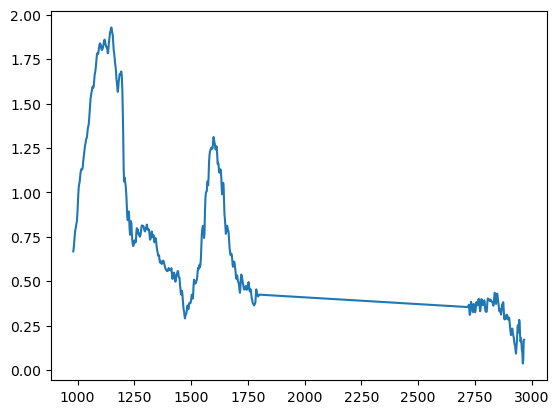

In [28]:
_ = plt.plot(preposs_data_ir.query('id =="MEC_04_054_Blank_AlSi_Active_20240414_S6_20250320_49"').iloc[:,:-4].T)

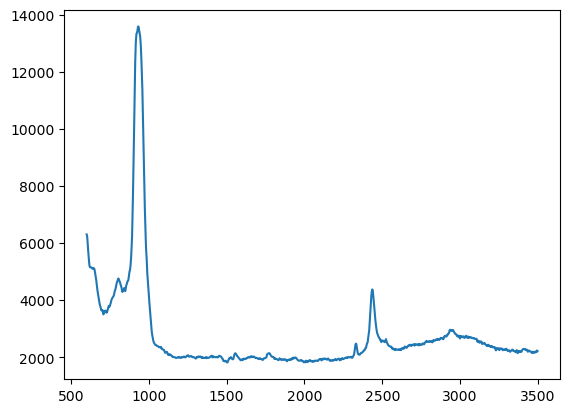

In [26]:
_ = plt.plot(preposs_data_raman.query('id =="MEC_04_054_Blank_AlSi_Active_20240414_S6_20250320_49"').iloc[:,:-4].T)

In [29]:
preposs_data_raman = pd.DataFrame(raman_final)
preposs_data_raman.columns = XX_raman
preposs_data_raman = pd.concat([preposs_data_raman, coords], axis=1)
preposs_data_raman['id'] = ids_file_name
preposs_data_raman['wn_saturated'] = [x.shape[0] for x in saturated_wn_list]

#preposs_data_raman_norm = preposs_data_raman.copy()
#preposs_data_raman_norm.iloc[:,:-4] = (preposs_data_raman_norm.iloc[:,:-4] - preposs_data_raman_norm.iloc[:,:-4].mean(1)[:,None])/preposs_data_raman_norm.iloc[:,:-4].std(1)[:,None]
#preposs_data_raman_norm.iloc[np.where(preposs_data_raman.iloc[:,:-4].std(1) == 0)[0], :-4] = 0

ids_no_signal = np.array(preposs_data_raman.query('id not in @ids_sat').iloc[np.where(np.sum(np.abs(np.diff(preposs_data_raman_norm.query('id not in @ids_sat').iloc[:,:-4], axis=1)), 1) < 7)[0],-2])
preposs_data_raman['no_signal'] = [(x in ids_no_signal)*1 for x in ids_file_name]
#preposs_data_raman = preposs_data_raman.loc[np.array(non_nas_idx), :].reset_index(drop=True)
preposs_data_raman['id_file'] = ['/'.join(x.split('/')[:-1]) for x in ids]
preposs_data_raman['type'] = type_blank
#preposs_data_raman.to_csv('enviromental_data/blank_data_raman_specy.csv')
preposs_data_raman.to_csv('enviromental_data/blank_data_raman_raw.csv')